In [1]:
import io
import os
import pandas as pd
import paramiko

import matplotlib.pyplot as plt

In [2]:

# --- 提供いただいたヘッダー見本（タブ区切りテキスト） ---
raw_header_text = """Timestamp (end of interval)	Int Temp (ｰC)	Ext Temp (ｰC)	Pressure (hPa)	Rel Humidity (%)	Wiper count	Vbatt (V)	40m Wind Speed (m/s)	40m Wind Speed Dispersion (m/s)	40m Wind Speed min (m/s)	40m Wind Speed max (m/s)	40m Wind Direction (ｰ)	40m Z-wind (m/s)	40m Z-wind Dispersion (m/s)	40m CNR (dB)	40m CNR min (dB)	40m Dopp Spect Broad (m/s)	40m Data Availability (%)		60m Wind Speed (m/s)	60m Wind Speed Dispersion (m/s)	60m Wind Speed min (m/s)	60m Wind Speed max (m/s)	60m Wind Direction (ｰ)	60m Z-wind (m/s)	60m Z-wind Dispersion (m/s)	60m CNR (dB)	60m CNR min (dB)	60m Dopp Spect Broad (m/s)	60m Data Availability (%)		80m Wind Speed (m/s)	80m Wind Speed Dispersion (m/s)	80m Wind Speed min (m/s)	80m Wind Speed max (m/s)	80m Wind Direction (ｰ)	80m Z-wind (m/s)	80m Z-wind Dispersion (m/s)	80m CNR (dB)	80m CNR min (dB)	80m Dopp Spect Broad (m/s)	80m Data Availability (%)		100m Wind Speed (m/s)	100m Wind Speed Dispersion (m/s)	100m Wind Speed min (m/s)	100m Wind Speed max (m/s)	100m Wind Direction (ｰ)	100m Z-wind (m/s)	100m Z-wind Dispersion (m/s)	100m CNR (dB)	100m CNR min (dB)	100m Dopp Spect Broad (m/s)	100m Data Availability (%)		120m Wind Speed (m/s)	120m Wind Speed Dispersion (m/s)	120m Wind Speed min (m/s)	120m Wind Speed max (m/s)	120m Wind Direction (ｰ)	120m Z-wind (m/s)	120m Z-wind Dispersion (m/s)	120m CNR (dB)	120m CNR min (dB)	120m Dopp Spect Broad (m/s)	120m Data Availability (%)		140m Wind Speed (m/s)	140m Wind Speed Dispersion (m/s)	140m Wind Speed min (m/s)	140m Wind Speed max (m/s)	140m Wind Direction (ｰ)	140m Z-wind (m/s)	140m Z-wind Dispersion (m/s)	140m CNR (dB)	140m CNR min (dB)	140m Dopp Spect Broad (m/s)	140m Data Availability (%)		160m Wind Speed (m/s)	160m Wind Speed Dispersion (m/s)	160m Wind Speed min (m/s)	160m Wind Speed max (m/s)	160m Wind Direction (ｰ)	160m Z-wind (m/s)	160m Z-wind Dispersion (m/s)	160m CNR (dB)	160m CNR min (dB)	160m Dopp Spect Broad (m/s)	160m Data Availability (%)		180m Wind Speed (m/s)	180m Wind Speed Dispersion (m/s)	180m Wind Speed min (m/s)	180m Wind Speed max (m/s)	180m Wind Direction (ｰ)	180m Z-wind (m/s)	180m Z-wind Dispersion (m/s)	180m CNR (dB)	180m CNR min (dB)	180m Dopp Spect Broad (m/s)	180m Data Availability (%)		200m Wind Speed (m/s)	200m Wind Speed Dispersion (m/s)	200m Wind Speed min (m/s)	200m Wind Speed max (m/s)	200m Wind Direction (ｰ)	200m Z-wind (m/s)	200m Z-wind Dispersion (m/s)	200m CNR (dB)	200m CNR min (dB)	200m Dopp Spect Broad (m/s)	200m Data Availability (%)		220m Wind Speed (m/s)	220m Wind Speed Dispersion (m/s)	220m Wind Speed min (m/s)	220m Wind Speed max (m/s)	220m Wind Direction (ｰ)	220m Z-wind (m/s)	220m Z-wind Dispersion (m/s)	220m CNR (dB)	220m CNR min (dB)	220m Dopp Spect Broad (m/s)	220m Data Availability (%)		240m Wind Speed (m/s)	240m Wind Speed Dispersion (m/s)	240m Wind Speed min (m/s)	240m Wind Speed max (m/s)	240m Wind Direction (ｰ)	240m Z-wind (m/s)	240m Z-wind Dispersion (m/s)	240m CNR (dB)	240m CNR min (dB)	240m Dopp Spect Broad (m/s)	240m Data Availability (%)		260m Wind Speed (m/s)	260m Wind Speed Dispersion (m/s)	260m Wind Speed min (m/s)	260m Wind Speed max (m/s)	260m Wind Direction (ｰ)	260m Z-wind (m/s)	260m Z-wind Dispersion (m/s)	260m CNR (dB)	260m CNR min (dB)	260m Dopp Spect Broad (m/s)	260m Data Availability (%)		280m Wind Speed (m/s)	280m Wind Speed Dispersion (m/s)	280m Wind Speed min (m/s)	280m Wind Speed max (m/s)	280m Wind Direction (ｰ)	280m Z-wind (m/s)	280m Z-wind Dispersion (m/s)	280m CNR (dB)	280m CNR min (dB)	280m Dopp Spect Broad (m/s)	280m Data Availability (%)		300m Wind Speed (m/s)	300m Wind Speed Dispersion (m/s)	300m Wind Speed min (m/s)	300m Wind Speed max (m/s)	300m Wind Direction (ｰ)	300m Z-wind (m/s)	300m Z-wind Dispersion (m/s)	300m CNR (dB)	300m CNR min (dB)	300m Dopp Spect Broad (m/s)	300m Data Availability (%)"""

clean_headers = [c.strip() for c in raw_header_text.split("\t") if c.strip() != ""]

# --- SFTP接続設定 ---
sftp_host = "172.16.34.223"
sftp_user = "hayashi"
sftp_pass = "hayashi"
remote_dir = "/home/hayashi/kaiseki/SampleData/FREA_LiDAR/WLS71045_sta_files/"

# 1. ここで確実にSSHとSFTPの接続を行います
ssh = paramiko.SSHClient()
ssh.set_missing_host_key_policy(paramiko.AutoAddPolicy())
ssh.connect(sftp_host, username=sftp_user, password=sftp_pass)
sftp = ssh.open_sftp()  # ここで 'sftp' が定義されます

df_list = []

try:
    # 2. 接続が確立された状態でループを回します
    for n in range(1, 29):
        date_str = f"{n:02d}"
        file_name = f"WLS71045_2025_02_{date_str}__00_10_00.sta"
        remote_path = os.path.join(remote_dir, file_name)

        print(f"ファイルを処理中: {file_name}")

        try:
            with sftp.open(remote_path, "rb") as f:
                binary_data = f.read()

            text_data = binary_data.decode("shift_jis", errors="ignore")

            df_raw = pd.read_csv(
                io.StringIO(text_data),
                sep="\s+",
                skiprows=42,
                header=None,
            )

            if df_raw.empty:
                print(f"⚠️ {file_name} はデータが空のためスキップします。")
                continue

            # 日時の結合
            combined_datetime = pd.to_datetime(
                df_raw[0].astype(str) + " " + df_raw[1].astype(str),
                errors="coerce",
            )

            df_clean = pd.DataFrame()
            df_clean[0] = combined_datetime

            # 残りのデータ列を結合
            df_data_part = df_raw.iloc[:, 2:]
            df_clean = pd.concat([df_clean, df_data_part], axis=1)
            df_clean.columns = range(df_clean.shape[1])

            # 列名のマッピング
            final_columns = []
            actual_cols = df_clean.shape[1]
            for i in range(actual_cols):
                if i < len(clean_headers):
                    final_columns.append(clean_headers[i])
                else:
                    final_columns.append(f"Extra_Column_{i}")
            df_clean.columns = final_columns

            df_list.append(df_clean)

        except FileNotFoundError:
            print(
                f"⚠️ ファイルが存在しません（スキップします）: {file_name}"
            )
        except Exception as file_error:
            print(f"❌ ファイル {file_name} の処理中にエラー: {file_error}")

    # すべてのファイルを縦結合
    if df_list:
        print("\n全ファイルを1つのDataFrameに統合中...")
        df_all = pd.concat(df_list, axis=0, ignore_index=True)

        print("\n🎉 全ファイルの統合・整形が完全に成功しました！")
        print("最終データ形状（合計行数, 列数）:", df_all.shape)
        print("\n--- データの最初の3行 ---")
        print(df_all.head(3))
    else:
        print("\n⚠️ 有効なデータが1つも見つかりませんでした。")

except Exception as e:
    print(f"\n❌ エラーが発生しました: {e}")

finally:
    # 3. 最後に安全にクローズします
    sftp.close()
    ssh.close()

ファイルを処理中: WLS71045_2025_02_01__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_02__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_03__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_04__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_05__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_06__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_07__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_08__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_09__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_10__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_11__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_12__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_13__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_14__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_15__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_16__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_17__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_18__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_19__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_20__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_21__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_22__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_23__0

In [2]:
df=pd.read_pickle("Sample_30minave.pkl")

In [3]:
df

,Timestamp (end of interval),Int Temp (ｰC),Ext Temp (ｰC),Pressure (hPa),Rel Humidity (%),Wiper count,Vbatt (V),40m Wind Speed (m/s),40m Wind Speed Dispersion (m/s),40m Wind Speed min (m/s),...,300m Wind Speed Dispersion (m/s),300m Wind Speed min (m/s),300m Wind Speed max (m/s),300m Wind Direction (ｰ),300m Z-wind (m/s),300m Z-wind Dispersion (m/s),300m CNR (dB),300m CNR min (dB),300m Dopp Spect Broad (m/s),300m Data Availability (%)
0,2025-02-01 00:30:00,4.466667,0.590000,988.016667,78.873333,0.0,NaN,2.043333,1.040000,0.163333,...,2.196667,0.883333,12.006667,232.123790,0.586667,1.376667,-11.786667,-18.270000,0.023333,100.0
1,2025-02-01 01:00:00,3.533333,0.590000,987.990000,79.410000,0.0,NaN,3.160000,1.213333,0.796667,...,1.890000,1.296667,10.803333,218.231922,0.286667,1.260000,-11.250000,-16.693333,0.020000,100.0
2,2025-02-01 01:30:00,2.700000,0.650000,988.166667,78.470000,0.0,NaN,2.350000,1.050000,0.333333,...,1.763333,0.390000,9.263333,222.405186,0.496667,1.370000,-11.196667,-17.030000,0.023333,100.0
3,2025-02-01 02:00:00,2.400000,0.466667,988.323333,79.826667,0.0,NaN,2.556667,1.073333,0.193333,...,1.896667,1.343333,11.126667,234.854207,0.563333,1.086667,-9.623333,-14.040000,0.020000,100.0
4,2025-02-01 02:30:00,3.400000,0.246667,988.110000,82.823333,0.0,NaN,2.806667,0.960000,0.966667,...,1.803333,0.740000,9.740000,233.100405,0.426667,1.206667,-9.653333,-13.953333,0.020000,100.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1339,2025-02-28 22:00:00,6.400000,168.853333,987.090000,43.543333,0.0,NaN,4.780000,1.210000,2.156667,...,1.130000,9.020000,15.636667,234.226927,-0.426667,0.636667,-19.723333,-21.213333,0.070000,100.0
1340,2025-02-28 22:30:00,6.400000,201.300000,987.263333,26.830000,0.0,NaN,4.796667,1.106667,2.430000,...,1.056667,6.656667,12.693333,226.430044,0.023333,0.526667,-19.623333,-21.170000,0.050000,100.0
1341,2025-02-28 23:00:00,6.400000,178.696667,987.350000,37.300000,0.0,NaN,3.806667,0.960000,1.383333,...,1.036667,4.386667,10.333333,223.080904,0.303333,0.656667,-19.540000,-20.993333,0.060000,100.0
1342,2025-02-28 23:30:00,6.400000,164.613333,987.116667,43.473333,0.0,NaN,3.910000,1.143333,1.113333,...,1.486667,2.420000,11.186667,202.908170,0.303333,0.783333,-19.573333,-21.030000,0.070000,100.0


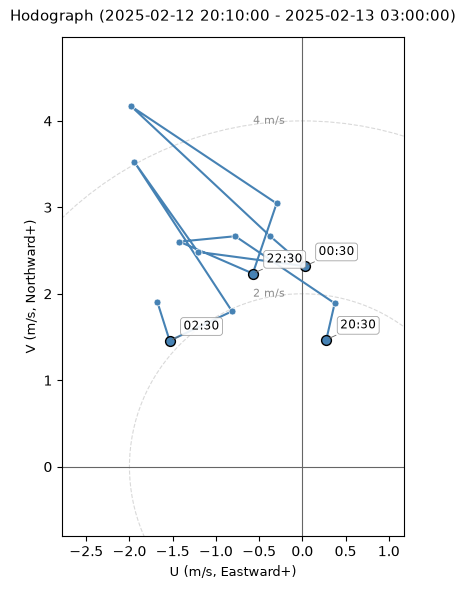

In [19]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", "40m Wind Speed (m/s)", "40m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df["40m Wind Speed (m/s)"], df["40m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

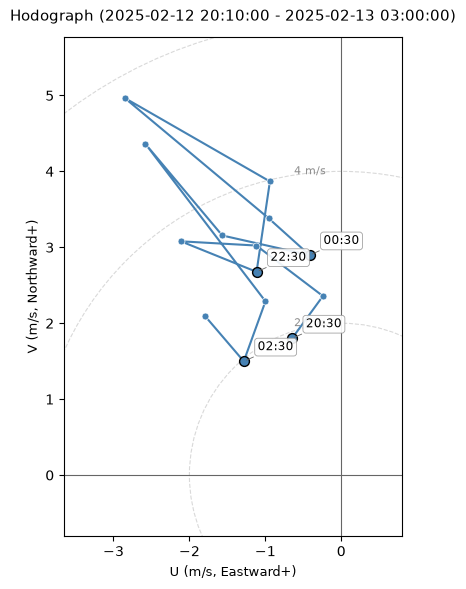

In [23]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", "60m Wind Speed (m/s)", "60m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df["60m Wind Speed (m/s)"], df["60m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

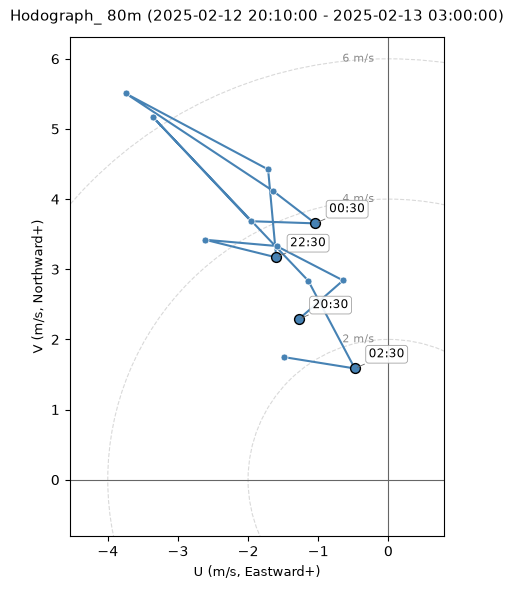

In [25]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=80
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

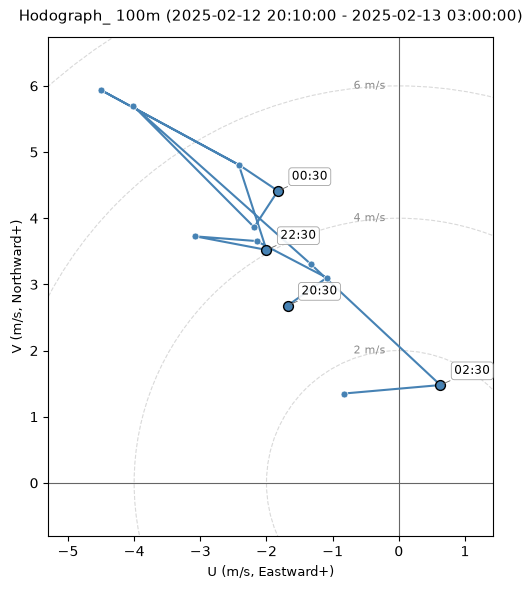

In [26]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=100
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

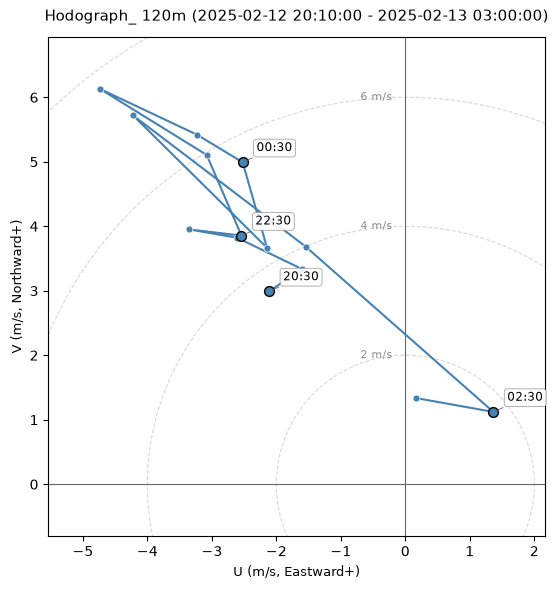

In [27]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=120
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

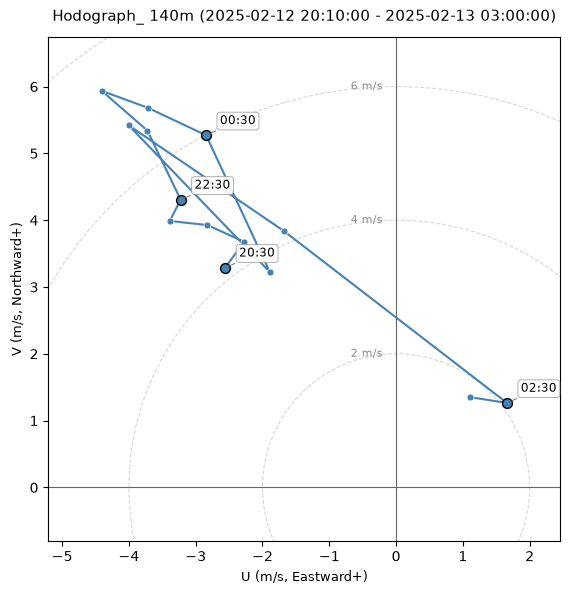

In [28]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=140
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

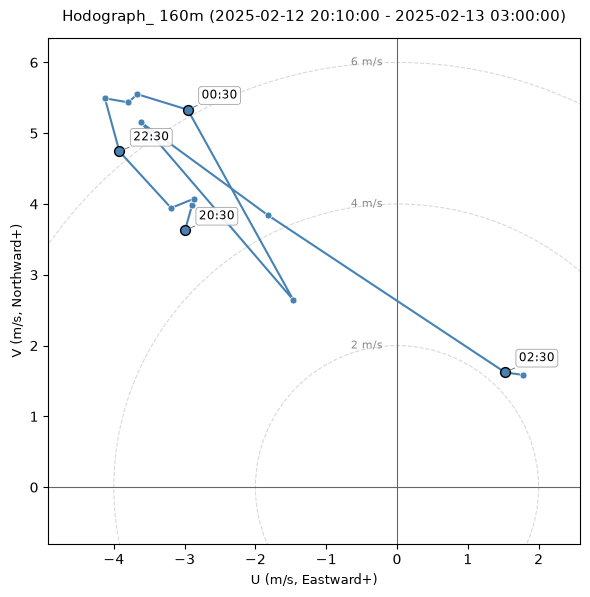

In [29]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=160
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

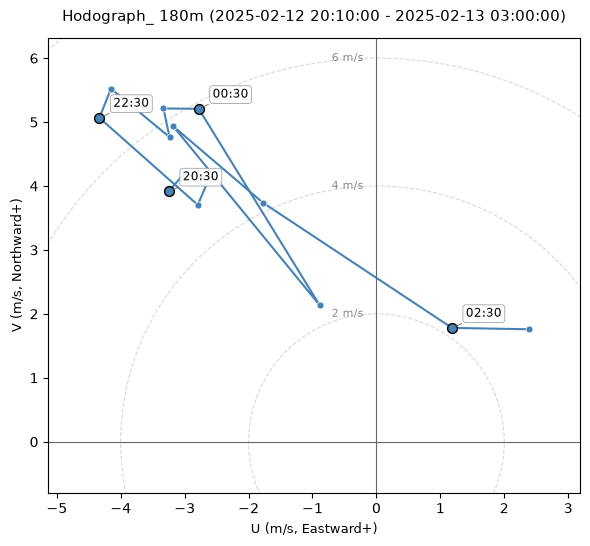

In [30]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=180
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

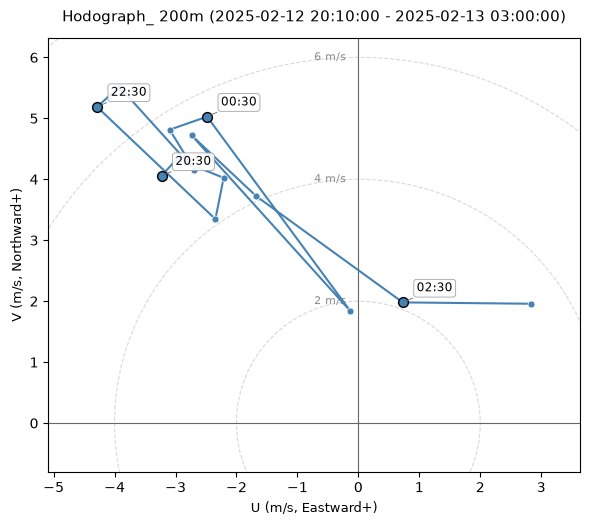

In [31]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=200
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

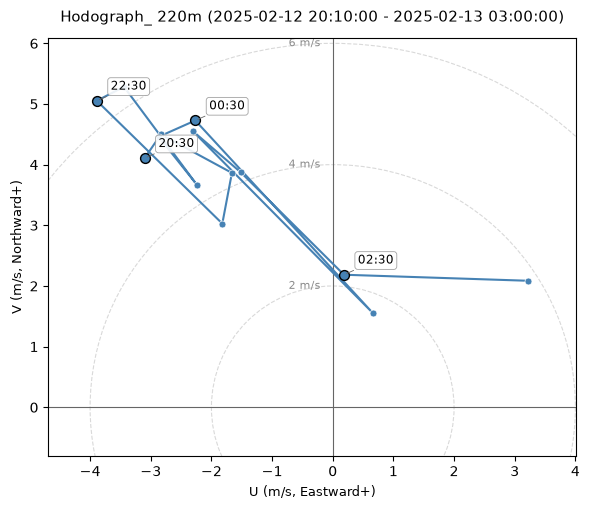

In [32]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=220
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

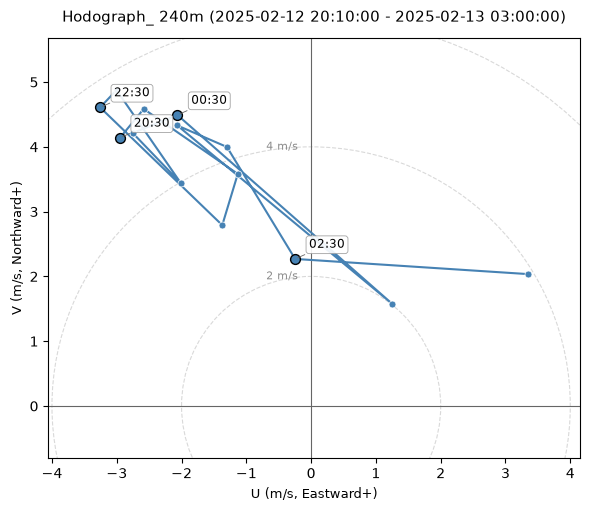

In [33]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=240
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

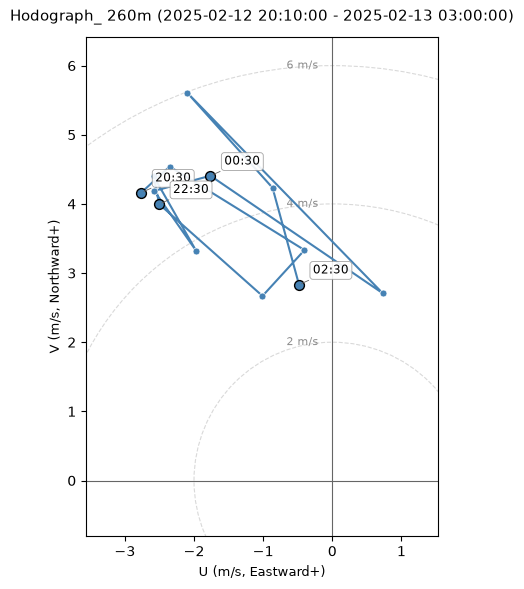

In [34]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=260
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

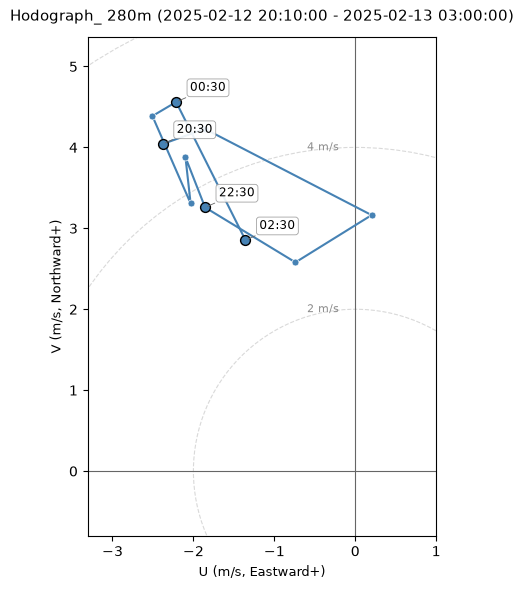

In [4]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=280
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

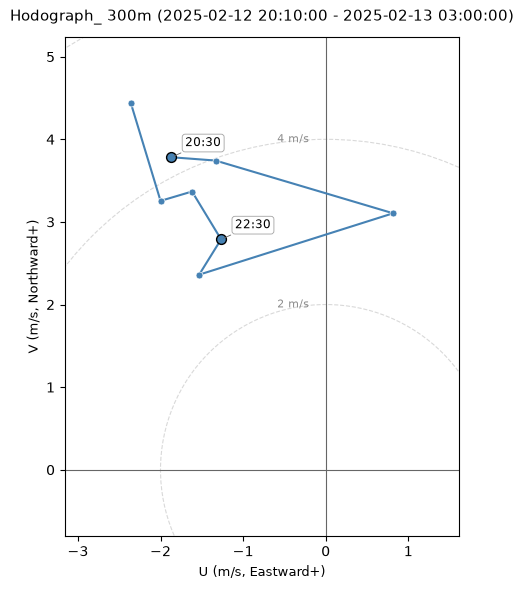

In [5]:
# Ensure the timestamp is always a column before later code does df.set_index("Timestamp (end of interval)")
n=300
df=pd.read_pickle("Sample_30minave.pkl")
hodograph_data = (
    df.reset_index()
    if "Timestamp (end of interval)" not in df.columns
    else df.copy()
)[["Timestamp (end of interval)", f"{n}m Wind Speed (m/s)", f"{n}m Wind Direction (ｰ)"]].dropna().copy()
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = hodograph_data

# ===== ① 期間設定 =====
start_time = "2025-02-12 20:10:00"
end_time = "2025-02-13 03:00:00"

# ===== ② データ整形 =====
df = df.set_index("Timestamp (end of interval)").sort_index()


def wind_to_uv(speed, direction_deg):
  rad = np.deg2rad(direction_deg)
  u = -speed * np.sin(rad)
  v = -speed * np.cos(rad)
  return u, v


df["U"], df["V"] = wind_to_uv(
    df[f"{n}m Wind Speed (m/s)"], df[f"{n}m Wind Direction (ｰ)"]
)

# ===== ③ 10分データの切り出し =====
plot_df = df.loc[start_time:end_time].dropna().copy()
plot_df["speed"] = np.sqrt(plot_df["U"] ** 2 + plot_df["V"] ** 2)

# ===== ④ ホドグラフ描画 =====
fig, ax = plt.subplots(figsize=(6, 6))

u_vals = plot_df["U"].values
v_vals = plot_df["V"].values

# 1. 表示範囲の計算（原点を含めつつデータ周辺にズーム）
margin = 0.8
u_min = min(u_vals.min(), 0) - margin
u_max = max(u_vals.max(), 0) + margin
v_min = min(v_vals.min(), 0) - margin
v_max = max(v_vals.max(), 0) + margin

# 2. 同心円（風速目安）と枠内ラベル
max_speed = np.ceil(plot_df["speed"].max())
for r in np.arange(2, max_speed + 2, 2):
  circle = plt.Circle(
      (0, 0),
      r,
      fill=False,
      color="0.85",
      lw=0.8,
      linestyle="--",
      zorder=1,
  )
  ax.add_patch(circle)

  # ラベルを枠内（V軸のすぐ左側）に固定して飛び出しを防止
  if v_min <= r <= v_max:
    ax.text(
        -0.2,
        r,
        f"{r:.0f} m/s",
        fontsize=8,
        color="0.55",
        ha="right",
        va="center",
        zorder=1,
    )

# 3. 原点・軸
ax.axhline(0, color="0.4", lw=0.8, zorder=1)
ax.axvline(0, color="0.4", lw=0.8, zorder=1)

# 4. 軌跡（矢印なしのシンプルな実線）
ax.plot(u_vals, v_vals, color="steelblue", lw=1.5, zorder=2)

# 5. プロット点
ax.scatter(
    u_vals,
    v_vals,
    color="steelblue",
    s=25,
    edgecolor="white",
    linewidth=0.5,
    zorder=3,
)

# 6. 時刻アノテーション（開始時刻からきっかり3時間毎）
# 21:10 -> 00:10 のように3時間(180分)間隔のタイムスタンプを抽出
label_times = pd.date_range(
    start=plot_df.index[0], end=plot_df.index[-1], freq="2h"
)

for t in label_times:
  # 最も近い観測点を取得
  idx = plot_df.index.get_indexer([t], method="nearest")[0]
  actual_t = plot_df.index[idx]
  u = plot_df["U"].iloc[idx]
  v = plot_df["V"].iloc[idx]

  ax.scatter(u, v, color="steelblue", s=50, edgecolor="black", zorder=4)
  ax.annotate(
      actual_t.strftime("%H:%M"),
      xy=(u, v),
      xytext=(10, 8),
      textcoords="offset points",
      fontsize=8.5,
      bbox=dict(
          boxstyle="round,pad=0.25", fc="white", ec="0.6", lw=0.6, alpha=0.9
      ),
      arrowprops=dict(arrowstyle="-", color="0.4", lw=0.6, shrinkA=2, shrinkB=2),
      zorder=5,
  )

ax.set_xlim(u_min, u_max)
ax.set_ylim(v_min, v_max)
ax.set_aspect("equal", "box")

ax.set_xlabel("U (m/s, Eastward+)", fontsize=9)
ax.set_ylabel("V (m/s, Northward+)", fontsize=9)
ax.set_title(f"Hodograph_ {n}m ({start_time} - {end_time})", pad=12, fontsize=11)

plt.tight_layout()
plt.show()

In [18]:
col_name = "Timestamp (end of interval)"
df=pd.read_pickle("Sample_30minave.pkl")
# 1. 日時型に変換してインデックスに設定し、日時順に並び替え
df[col_name] = pd.to_datetime(df[col_name])
df = df.set_index(col_name).sort_index()

# 2. 開始時刻〜終了時刻を指定して抽出
start_time = "2025-02-12 22:00:00"
end_time = "2025-02-13 03:00:00"

extracted_df = df.loc[start_time:end_time]
print(extracted_df)


                             Int Temp (ｰC)  Ext Temp (ｰC)  Pressure (hPa)  \
Timestamp (end of interval)                                                 
2025-02-12 22:00:00               3.066667         555.35         5555.35   
2025-02-12 22:30:00               2.700000         555.35         5555.35   
2025-02-12 23:00:00               2.400000         555.35         5555.35   
2025-02-12 23:30:00               3.166667         555.35         5555.35   
2025-02-13 00:00:00               4.433333         555.35         5555.35   
2025-02-13 00:30:00               3.600000         555.35         5555.35   
2025-02-13 01:00:00               3.600000         555.35         5555.35   
2025-02-13 01:30:00               3.066667         555.35         5555.35   
2025-02-13 02:00:00               2.800000         555.35         5555.35   
2025-02-13 02:30:00               3.233333         555.35         5555.35   
2025-02-13 03:00:00               3.000000         555.35         5555.35   

In [19]:
extracted_df.to_csv("extracted_result.csv")